<h1 align = "center">
Rwanda Maize-Urea Trial
</h1>

<h2 align = "center">
Treatment Effect Analysis
</h2> 

# Objective

Our main objective here is to determine whether differences in maize yield across the four Urea treatments remain meaningful after accounting for season, mega-environment, and the fact that plots from the same field share growing conditions.

- We now have enough descriptive analysis from our EDA Notebook that we think motivates the next stage, formal treatment-effect analysis. 

- Here, we want to estimate treatment effects while accounting for the experimental design. 

    - Since the four treatments were assigned to plots within fields, we want to account for the shared field context rather than treating all 1,598 plots as completely independent observations.

- We want to begin with a treatment-effect model that includes treatment, season, mega-environment, and their relevant interactions, while accounting for field-level grouping. 

    - But before fitting it, we want to check that the field identifiers and treatment allocation can be represented appropriately in the model.

        - This should help us answer the more important question: *Are the observed yield differences sufficiently strong and consistent to support conclusions about treatment performance, once field and environmental variation are considered?*

## Baseline Treatment-Effect Model

Without complicating the analysis upfront, we want to first fit the baseline treatment-effect model

**Why use a mixed-effects model?**

Our plots are grouped within fields, and each field was intended to contain plots receiving different treatments. 

- Plots from the same field are therefore not fully independent.

A linear mixed-effects model lets us estimate treatment differences while accounting for shared field-level conditions. We'll include:

- **Treatment** - *the main factor of interest.*

- **Season** - *to account for differences between 21A, 22A, and 22B.*

- **Mega-environment** - *to account for broad growing-environment differences.*

- **Field-season** - *as a random intercept to account for plots sharing the same experimental field in a season.*

This first model estimates adjusted treatment differences. It does not, by itself, establish that treatment assignment was randomized or prove causality.

### Imports and Setup

In [1]:
import pandas as pd
import numpy as np

import warnings
warnings.filterwarnings("ignore")

In [2]:
from pathlib import Path

# Define path to folder
data_path = Path(r"../01_Data/processed")

def load_csv(filename):
    return pd.read_csv(data_path/filename)

In [3]:
plot_with_field_soil = load_csv("plot_with_field_soil.csv")
plot_with_field_soil.head()

,block_id,season,plot_id,treat_code,treat_details,urea_rate_timing,crop,prior_season_crop,planting_date,compost_tha,...,check_planting_date_before_harvest_date,days_silking_to_R3,calculated_urea_total,urea_total_difference,meg_env,_merge,pH,soil_match,has_soil_record,has_field_match
0,adfa31ad-95bf-453d-94f1-d163a97756ee,21A,adfa31ad-95bf-453d-94f1-d163a97756ee-21A-A,A,DAP 1Kg/Are + Urea 0.5Kg/Are at V6,Urea 0.5Kg/Are(V6),maize,maize,9/26/2020,8,...,False,20.0,50,0,Low-Mid-Dry,both,5.21,both,True,True
1,adfa31ad-95bf-453d-94f1-d163a97756ee,21A,adfa31ad-95bf-453d-94f1-d163a97756ee-21A-B,B,DAP 1Kg/Are + Urea 0.5Kg/Are at Planting and U...,Urea1kg/Are(Planting+V6),maize,maize,9/26/2020,8,...,False,20.0,100,0,Low-Mid-Dry,both,NaN,left_only,False,True
2,adfa31ad-95bf-453d-94f1-d163a97756ee,21A,adfa31ad-95bf-453d-94f1-d163a97756ee-21A-C,C,DAP 1Kg/Are + Urea 0.5Kg/Are at V6 + Urea 0.5K...,Urea 1kg/Are(V6 + V10),maize,maize,9/26/2020,8,...,False,20.0,100,0,Low-Mid-Dry,both,NaN,left_only,False,True
3,adfa31ad-95bf-453d-94f1-d163a97756ee,21A,adfa31ad-95bf-453d-94f1-d163a97756ee-21A-D,D,DAP 1Kg/Are at planting+ Urea 1Kg/Are at V6,Urea 1kg/Are(V6),maize,maize,9/26/2020,8,...,False,20.0,100,0,Low-Mid-Dry,both,NaN,left_only,False,True
4,d8807f25-e675-49ae-87a3-d228eca23c72,21A,d8807f25-e675-49ae-87a3-d228eca23c72-21A-A,A,DAP 1Kg/Are + Urea 0.5Kg/Are at V6,Urea 0.5Kg/Are(V6),maize,maize,9/26/2020,10,...,False,20.0,50,0,Low-Mid-Dry,both,5.75,both,True,True


Moveing forward with the analysis, we want to create a separate analysis copy to our plot_with_field_soil.csv so the original remains unchanged

In [4]:
import statsmodels.formula.api as smf

# Keep plots with the field context needed for this model.
# Five plots lack a matching mega-environment.
analysis_df = plot_with_field_soil.dropna(
    subset=["meg_env"]
).copy()

# Identify each field within its season.
analysis_df["field_season_id"] = (
    analysis_df["block_id"].astype(str)
    + "_"
    + analysis_df["season"].astype(str)
)

# Set the 50 kg/ha treatment as the reference category.
treatment_order = [
    "Urea 0.5Kg/Are(V6)",
    "Urea1kg/Are(Planting+V6)",
    "Urea 1kg/Are(V6)",
    "Urea 1kg/Are(V6 + V10)"
]

analysis_df["urea_rate_timing"] = pd.Categorical(
    analysis_df["urea_rate_timing"],
    categories=treatment_order
)

# Fit the baseline mixed-effects model.
model = smf.mixedlm(
    "yield_tha ~ C(urea_rate_timing) + C(season) + C(meg_env)",
    data=analysis_df,
    groups=analysis_df["field_season_id"]
)

model_result = model.fit(reml=True)

print(model_result.summary())

                          Mixed Linear Model Regression Results
Model:                        MixedLM            Dependent Variable:            yield_tha 
No. Observations:             1593               Method:                        REML      
No. Groups:                   399                Scale:                         2.0696    
Min. group size:              3                  Log-Likelihood:                -3163.7807
Max. group size:              4                  Converged:                     Yes       
Mean group size:              4.0                                                         
------------------------------------------------------------------------------------------
                                                Coef.  Std.Err.   z    P>|z| [0.025 0.975]
------------------------------------------------------------------------------------------
Intercept                                        3.690    0.198 18.601 0.000  3.301  4.079
C(urea_rate_timing)[T.Urea

### **What we can draw from the baseline model**

Our model converges successfully and uses 1,593 plots across 399 field-season groups. 

- This is a good starting point for estimating treatment differences while accounting for shared field conditions.

The main finding:

- Both 100 kg/ha treatments applied entirely or partly later in the season show higher estimated yields than the 50 kg/ha treatment, after adjusting for season and mega-environment.

- Adjusted treatment comparisons:

| Treatment comparison | Estimated yield difference (t/ha) | 95% confidence interval | p-value |
|---|---:|---:|---:|
| 100 kg/ha, split between planting and V6 | +0.144 | −0.056 to +0.344 | 0.158 |
| 100 kg/ha, entirely at V6 | +0.546 | +0.346 to +0.745 |   |

The reference treatment is 50 kg/ha applied entirely at V6.

### Test Treatment Consistency

We've already established the baseline model our next important question is: **Does the treatment ranking change across mega-environments?**

We want to compare a model with common treatment effects across mega-environments against one that allows treatment effects to vary by mega-environments.

In [5]:
from scipy.stats import chi2

# Fit both models using maximum likelihood for a fair comparison
base_ml = smf.mixedlm(
    "yield_tha ~ C(urea_rate_timing) + C(season) + C(meg_env)",
    data=analysis_df,
    groups=analysis_df["field_season_id"]
).fit(reml=False)

me_interaction_ml = smf.mixedlm(
    "yield_tha ~ C(urea_rate_timing) * C(meg_env) + C(season)",
    data=analysis_df,
    groups=analysis_df["field_season_id"]
).fit(reml=False)

lr_stat = 2 * (me_interaction_ml.llf - base_ml.llf)

df_diff = (
    len(me_interaction_ml.fe_params)
    - len(base_ml.fe_params)
)

p_value = chi2.sf(lr_stat, df_diff)

print(f"Likelihood-ratio statistic: {lr_stat:.3f}")
print(f"Degrees of freedom: {df_diff}")
print(f"P-value: {p_value:.6f}")

Likelihood-ratio statistic: 9.142
Degrees of freedom: 9
P-value: 0.424245


What we can draw from the result above is that there isn't sufficient evidence that treatment effects differ across mega-environments at the 5% significance level. 

This does not, however, prove that the treatments perform identically across environments. It only means that, given these data and this model, adding the interaction did not significantly improve the fit.

For now, we are retaining the simpler model as our primary model, while recognizing that season-specific treatment differences have not yet been tested.

### Direct Treatment Comparison

We now want to compare all four treatments directly: Our baseline model compared each treatment with the 50 kg/ha V6 treatment. 

We now need direct comparisons among the three 100 kg/ha treatments to answer the practical question: 

- **Does applying all 100 kg/ha at V6 produce a significantly different yield from splitting the same total amount between V6 and V10, or between planting and V6?**

In [6]:
from itertools import combinations
from scipy.stats import norm
from statsmodels.stats.multitest import multipletests

# Fixed-effect estimates and covariance matrix from the baseline ML model
fe = base_ml.fe_params
cov = base_ml.cov_params().loc[fe.index, fe.index]

# Build predictions at the same season and mega-environment
# distribution for each treatment, then average across observations.
from patsy import build_design_matrices

design_info = base_ml.model.data.design_info

treatments = list(treatment_order)
means = {}

for treatment in treatments:
    pred_df = analysis_df.copy()
    pred_df["urea_rate_timing"] = treatment

    X = np.asarray(
        build_design_matrices(
            [design_info],
            pred_df,
            return_type="dataframe"
        )[0]
    )

    means[treatment] = X @ fe.to_numpy()

# Average fixed-effect predictions for each treatment
mean_estimates = {
    treatment: values.mean()
    for treatment, values in means.items()
}

print("Adjusted mean yield estimates (t/ha):")
print(pd.Series(mean_estimates).round(3))

Adjusted mean yield estimates (t/ha):
Urea 0.5Kg/Are(V6)          4.571
Urea1kg/Are(Planting+V6)    4.715
Urea 1kg/Are(V6)            5.117
Urea 1kg/Are(V6 + V10)      5.071
dtype: float64


In [7]:
pairwise_results = []

for t1, t2 in combinations(treatments, 2):
    # Difference in predicted yield, t1 minus t2
    pred_df1 = analysis_df.copy()
    pred_df2 = analysis_df.copy()

    pred_df1["urea_rate_timing"] = t1
    pred_df2["urea_rate_timing"] = t2

    X1 = np.asarray(
        build_design_matrices(
            [design_info],
            pred_df1,
            return_type="dataframe"
        )[0]
    ).mean(axis=0)

    X2 = np.asarray(
        build_design_matrices(
            [design_info],
            pred_df2,
            return_type="dataframe"
        )[0]
    ).mean(axis=0)

    contrast = X1 - X2
    difference = float(contrast @ fe.to_numpy())
    se = float(np.sqrt(contrast @ cov.to_numpy() @ contrast))
    z = difference / se
    p = 2 * norm.sf(abs(z))

    pairwise_results.append({
        "Treatment 1": t1,
        "Treatment 2": t2,
        "Difference (t/ha)": difference,
        "SE": se,
        "P-value": p
    })

pairwise_df = pd.DataFrame(pairwise_results)

# Adjust the six pairwise p-values for multiple comparisons
pairwise_df["Tukey-adjusted p"] = multipletests(
    pairwise_df["P-value"],
    method="holm"
)[1]

print(
    pairwise_df.round(4).to_string(index=False)
)

             Treatment 1              Treatment 2  Difference (t/ha)     SE  P-value  Tukey-adjusted p
      Urea 0.5Kg/Are(V6) Urea1kg/Are(Planting+V6)            -0.1443 0.1020   0.1571            0.3143
      Urea 0.5Kg/Are(V6)         Urea 1kg/Are(V6)            -0.5458 0.1017   0.0000            0.0000
      Urea 0.5Kg/Are(V6)   Urea 1kg/Are(V6 + V10)            -0.5000 0.1017   0.0000            0.0000
Urea1kg/Are(Planting+V6)         Urea 1kg/Are(V6)            -0.4015 0.1020   0.0001            0.0003
Urea1kg/Are(Planting+V6)   Urea 1kg/Are(V6 + V10)            -0.3558 0.1020   0.0005            0.0015
        Urea 1kg/Are(V6)   Urea 1kg/Are(V6 + V10)             0.0458 0.1017   0.6528            0.6528


These results give us a clearer answer to the research question: 

- The adjusted mean yields are very close for the two treatments applying 100 kg/ha at later growth stages, while 

- both outperform the lower-rate treatment and the planting-plus-V6 split under this model.

**Adjusted mean yield by treatment**

|Treatment                          |Yield          |
|-----------------------------------|---------------|
|100 kg/ha - All at V6              |5.117 t/ha     |
|100 kg/ha - Split V6 + V10         |5.071 t/ha     |
|100 kg/ha - Split planting + V6    |4.715 t/ha     |
|50 kg/ha - All at V6               |4.571 t/ha     |

The highest estimated yield was achieved by applying 100 kg/ha entirely at V6 (5.117 t/ha), 

The second highest yield was achieved by splitting the same total between V6 and V10 (5.071 t/ha).

**Pairwise comparison**

| Comparison | Yield difference | Adjusted p-value | Interpretation |
|---|---:|---:|---|
| 100 kg/ha at V6 vs. 50 kg/ha at V6 | +0.546 t/ha |    |   |

### Validating the Treatment-effect Model

Before we can rely on our results bove, we want to establish two things:

- Does the model's residuals show substantial departures from its assumptions?

- Are the estimated treatment differences sensitive to the unusually high yield observation of the 50.1 t/ha

**So what are we looking for exactly?**

- **Residual vs fitted:** *we want to look for pronounced curves, changing spread, or other systematic patterns*

- **Q-Q plot:** we want to look for substantial departures from the diagonal, especially in the tails*

- **Sensitivity:** *we want to check whether removing the extreme observation materially changes the treatment coefficients*

Highest-yield observation:
block_id            1e641f3d-2512-43b4-beb6-839e28012d75
season                                               22B
meg_env                                      Low-Mid-Dry
urea_rate_timing                  Urea 1kg/Are(V6 + V10)
yield_tha                                           50.1
Name: 989, dtype: object


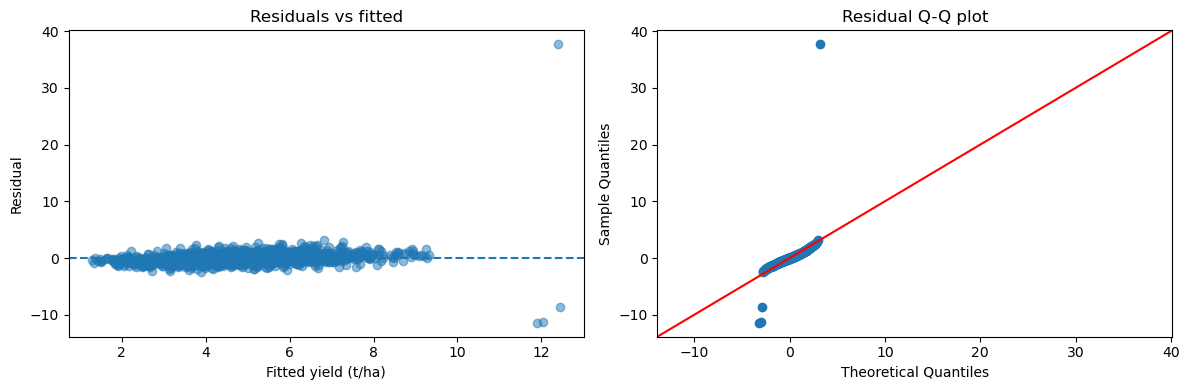


Treatment coefficient sensitivity:
                                                 Original estimate  \
C(urea_rate_timing)[T.Urea1kg/Are(Planting+V6)]             0.1443   
C(urea_rate_timing)[T.Urea 1kg/Are(V6)]                     0.5458   
C(urea_rate_timing)[T.Urea 1kg/Are(V6 + V10)]               0.5000   

                                                 Without extreme value  Change  
C(urea_rate_timing)[T.Urea1kg/Are(Planting+V6)]                 0.1453  0.0010  
C(urea_rate_timing)[T.Urea 1kg/Are(V6)]                         0.5458  0.0000  
C(urea_rate_timing)[T.Urea 1kg/Are(V6 + V10)]                   0.3799 -0.1201  


In [8]:

import matplotlib.pyplot as plt
import statsmodels.api as sm

# A. Inspect the highest-yield observation
extreme_idx = analysis_df["yield_tha"].idxmax()

print("Highest-yield observation:")
print(
    analysis_df.loc[
        extreme_idx,
        ["block_id", "season", "meg_env",
         "urea_rate_timing", "yield_tha"]
    ]
)

# B. Inspect residuals from the fitted baseline model
residuals = base_ml.resid
fitted = base_ml.fittedvalues

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].scatter(fitted, residuals, alpha=0.5)
axes[0].axhline(0, linestyle="--")
axes[0].set_xlabel("Fitted yield (t/ha)")
axes[0].set_ylabel("Residual")
axes[0].set_title("Residuals vs fitted")

sm.qqplot(residuals, line="45", ax=axes[1])
axes[1].set_title("Residual Q-Q plot")

plt.tight_layout()
plt.show()

# C. Refit the same model without the extreme observation
sensitivity_df = analysis_df.drop(index=extreme_idx).copy()

sensitivity_model = smf.mixedlm(
    "yield_tha ~ C(urea_rate_timing) + C(season) + C(meg_env)",
    data=sensitivity_df,
    groups=sensitivity_df["field_season_id"]
).fit(reml=False)

# Compare treatment estimates
treatment_terms = [
    term for term in base_ml.fe_params.index
    if "urea_rate_timing" in term
]

comparison = pd.DataFrame({
    "Original estimate": base_ml.fe_params[treatment_terms],
    "Without extreme value":
        sensitivity_model.fe_params[treatment_terms]
})

comparison["Change"] = (
    comparison["Without extreme value"]
    - comparison["Original estimate"]
)

print("\nTreatment coefficient sensitivity:")
print(comparison.round(4))


Our sensitivity analysis insinuates that **although the main treatment findings are fairly robust to the extreme observation, the estimated advantage of splitting Urea between V6 and V10 is sensitive to it**

**So what changes when we exclude the 50.10 t/ha observation?**

|Treatment vs. 50 kg/ha at V6	|Original coefficient	|Without extreme value	|Change|
|----|---:|---:|---:|
|100 kg/ha, split planting + V6	|+0.1443	|+0.1453	|+0.0010|
|100 kg/ha, all at V6	|+0.5458	|+0.5458	|0.0000|
|100 kg/ha, split V6 + V10	|+0.5000	|+0.3799	|−0.1201|

The coefficients represent adjusted yield difference in t/ha

**What this means**

- **100 kg/ha applied entirely at V6:** its estimated advantage is unchanged at approximately 0.55 t/ha. 
    
    - *This is reassuring evidence that this finding is not affected by the extreme observation*

- **100 kg/ha split between V6 and V10:** Its estimated advantage falls from 0.50 to 0.38 t/ha.
    
    - *The observation materially influences the size of this estimated advantage despite the coefficient remaining positive.*

- **100 kg/ha split between planting and V6:** The estimate barely changes

Importantly, this comparison examines coefficient stability, not statistical significance after exclusion.
- We haven't yet recalculated teh confidence intervals or pairwise tests for the sensitivity model

#### **Residuals diagnostic**

**Residuals vs Fitted values**

The main takeaway is that **most residuals appear reasonably concentrated around zero, with a few extreme observations stringly affecting the model diagnostics**

Comparing the model's fitted maize yields with the residuals, we observe that:

- **Residuals are centered around zero:** Most observations are clustered around zero, suggesting that the model does not have an obvious overall tendency to overpredict or underpredict across most fitted values.

- **No obvious curved pattern:** The main clud does not show a string systematic curve, implying there is no clear visual evidence of substantial nonlinearity in the fitted range.

- **Possible variation in residual spread:** The residuals appear relatively concentrated for most fitted values.
    - The caveat, though, is that the spread should be examined more carefully before we can conclude that the constant-variance assumption holds.

- **Extreme outliers:** A few observations have extreme residuals (at +38, -9 and -12) that are substantially larger in magnitude than the majority of residuals.
    - Deserve investigation.


#### **Residual Q-Q plot**

In comparing the distribution of the model residual with the distribution expected under normality, we observe that:

- **Most observations appear concentrated near the reference line:** It implies that the central portion of the residual distribution may be approximately normal.

- **Pronounced departures in the tails:** Several points fall far away from the reference line, especially at the upper end.

- **A very large positive residual:** One observation appears far above the main cluster, around a sample quantile of +38

- **Large negative resifual:** A few observations also deviate substantially in the lower tail. 

If the residuals are approximately normally distributed, the points should fall reasonably close to the reference line. 

These departures suggest that the residuals are **not normally distributed overall**; extreme observations are likely contributing substantially to the non-normality. 

### Testing Whether Treatment Effects Vary by Season

Here we want to answer the research question: **Does the relative performance of the four Urea treatments change between seasons 21A, 22A, and 22B?**

Our descriptive analysis from the eda notebook showed some difference in treatment rankings by season

We want to test whether these differences are statistically supported after accounting for mega-environment and shared field conditions.

In [9]:
from scipy.stats import chi2
import statsmodels.formula.api as smf

# Baseline model: common treatment effects across seasons
base_ml = smf.mixedlm(
    "yield_tha ~ C(urea_rate_timing) + C(season) + C(meg_env)",
    data=analysis_df,
    groups=analysis_df["field_season_id"]
).fit(reml=False)

# Allow treatment effects to vary by season
season_interaction_ml = smf.mixedlm(
    "yield_tha ~ C(urea_rate_timing) * C(season) + C(meg_env)",
    data=analysis_df,
    groups=analysis_df["field_season_id"]
).fit(reml=False)

# Compare the two nested models
lr_stat = 2 * (
    season_interaction_ml.llf - base_ml.llf
)

df_diff = (
    len(season_interaction_ml.fe_params)
    - len(base_ml.fe_params)
)

p_value = chi2.sf(lr_stat, df_diff)


**What we are looking for**

- **A p value below 0.05** implies there is evidence that treatment effects vary by season.

    - We'd therefore estimate adjusted treatment means and direct comparisons separately for each season

- **A p value higher than or equal to 0.05** implies there's no sufficient evidence of season-specific treatment effects

    - We'd therefore retain the simpler model for the primary conslusions, while still reporting the descriptive seasonal patterns

In [10]:
print(f"Likelihood-ratio statistic: {lr_stat:.3f}")
print(f"Degrees of freedom: {df_diff}")
print(f"P-value: {p_value:.6f}")

Likelihood-ratio statistic: 10.564
Degrees of freedom: 6
P-value: 0.102834


##### **What we can draw from the results**

At the conventional 5% level of significance, we do not have sufficient evidence that treatment effects differ across seasons. We can, therefore, conclude that:

- The treatment-by-season interaction did not significantly improve the model compared with the simpler model that assumes common treatment effects across seasons. 

    - This does not, however, prove that treatment effects are identicall in all three seasons; instead it implies that the observed differences are not strong enough to statistically establish seasonal variation. 

- Together with our mega-environment interaction test of 0.424, the evidence currently supports using the simpler model with common treatment effects as the primary analysis. 

    - We can still, however, show descriptive results by season and mega-environment to communicate observed variations. 

> These are likelihood-ratio tests for mixed models. Their conclusions rely on the models being correctly specified and fitted successfully; We should finish checking the diagnostics before we can treat the model as final. 

### Investigating Other Factors Associated with Maize Yield

Now that we've established the main treatment comparisons, we want to investigate whether other agronomic management factors help explain variation in yield.

- We'll begin with a focused exploratory model using:

    - Compost application rate (compost_tha)
    
    - Seed rate (seeds_kgha)

    - DAP fertilizer rate (dap_kgha)

    - Germination rate (gerimation_rate)

We want to retain treatment, season and mega-environment in our model and continue accounting for the field-seaon grouping.

- This should help with examining the association of these factors with yield while adjusting for the variables already included in our primary analysis. 

In [11]:

import pandas as pd
import statsmodels.formula.api as smf

# Candidate agronomic predictors
predictors = [
    "compost_tha",
    "seeds_kgha",
    "dap_kgha",
    "germination_rate"
]

driver_df = analysis_df.copy()

# Ensure candidate predictors are numeric
for col in predictors:
    driver_df[col] = pd.to_numeric(
        driver_df[col], errors="coerce"
    )

# Keep observations with complete data for this model
driver_df = driver_df.dropna(
    subset=[
        "yield_tha",
        "urea_rate_timing",
        "season",
        "meg_env",
        "field_season_id"
    ] + predictors
).copy()

print("Observations available:", len(driver_df))
print("Observations in baseline analysis:", len(analysis_df))

Observations available: 1593
Observations in baseline analysis: 1593


#### **What are we looking for?**

We want to focu on the coefficients for the four additional predictors:

|Predictor	|Interpretation|
|----|----|
|compost_tha	|Estimated yield difference associated with a one-unit increase in compost application|
|seeds_kgha	|Estimated yield difference associated with a one-unit increase in seed rate|
|dap_kgha	|Estimated yield difference associated with a one-unit increase in DAP application|
|germination_rate	|Estimated yield difference associated with a one-unit increase in the recorded germination rate|

We want to pay attention to each coefficient's sign, confidence interval and p-value.

We'll check the units of each variable before we can interpret the magnitude.

- For instance if germination rate is recorded on a 0-100 scale, it's coefficient will represent a one-percentage-point increase; if recorded from 0-1 the interpretation changes.

These are **adjusted associations, not necessarily causal effects**. Germination may itself be affected by treatment or growing conditions, and adding it to the model can change what the treatment coefficients represent.

We are also deliberately leaving soil pH out of this model because soil measurements are only available for only a subset of plots. 

- We'll examine soil pH separately and clearly state the limitation rather than silently reducing the sample for every analysis. 

In [12]:

# Fit exploratory yield-driver model
driver_model = smf.mixedlm(
    """
    yield_tha ~ C(urea_rate_timing)
    + C(season)
    + C(meg_env)
    + compost_tha
    + seeds_kgha
    + dap_kgha
    + germination_rate
    """,
    data=driver_df,
    groups=driver_df["field_season_id"]
).fit(reml=True)

print(driver_model.summary())


                          Mixed Linear Model Regression Results
Model:                        MixedLM            Dependent Variable:            yield_tha 
No. Observations:             1593               Method:                        REML      
No. Groups:                   399                Scale:                         2.0497    
Min. group size:              3                  Log-Likelihood:                -3161.4979
Max. group size:              4                  Converged:                     Yes       
Mean group size:              4.0                                                         
------------------------------------------------------------------------------------------
                                                Coef.  Std.Err.   z    P>|z| [0.025 0.975]
------------------------------------------------------------------------------------------
Intercept                                        7.330    5.788  1.266 0.205 -4.015 18.675
C(urea_rate_timing)[T.Urea

#### What This Tells Us

Our model converges successfully using all 1,593 observations across 399 field-season groups. 

- This is useful because adding the four agronomic variables does not reduce the sample size, thereby allowing us to compare the results directly with our baseline model.

The model asks: **After accounting for treatment, season, and mega-environment, which agronomic variables are associated with maize yield?**

**What we find**

| Variable | Coefficient | P-value | Interpretation |
|---|---:|---:|---|
| Compost application (compost_tha) | −0.040 | 0.142 | No statistically significant association detected |
| Seed rate (seeds_kgha) | −0.005 | 0.764 | No evidence of an independent association |
| DAP fertilizer (dap_kgha) | −0.051 | 0.390 | No statistically significant association detected |
| Germination rate (germination_rate) | +0.029 |    |   |


### Finalizing the Outlier Sensitivity Analysis

We previously identified one observation with a 50.1 t/ha yield in the V6 + V10 treatment, in season 22B and the Low-Mid-Dry mega-environment

We've seen that removing it reduces the estimated treatment coefficient from 0.500 to 0.380 t/ha relative to the 50 kg/ha reference treatment; the estimate for the 100 kg/ha all-at-V6 treatment remained at 0.546 t/ha.

This observation suggests the V6 + V10 estimate is quite sensitive to it. However, we still have to check whether the statistical conclusions change. 

What we want to to now is **fit the sensitivity model**

In [13]:
# Identify the extreme observation
extreme_mask = analysis_df["yield_tha"].eq(50.1)

print("Extreme observations:", extreme_mask.sum())

# Create a sensitivity dataset without the extreme observation
sensitivity_df = analysis_df.loc[~extreme_mask].copy()

print("Original observations:", len(analysis_df))
print("Sensitivity observations:", len(sensitivity_df))

# Refit the original treatment model
sensitivity_model = smf.mixedlm(
    """
    yield_tha ~ C(urea_rate_timing)
    + C(season)
    + C(meg_env)
    """,
    data=sensitivity_df,
    groups=sensitivity_df["field_season_id"]
).fit(reml=True)

print(sensitivity_model.summary())

Extreme observations: 1
Original observations: 1593
Sensitivity observations: 1592
                          Mixed Linear Model Regression Results
Model:                        MixedLM            Dependent Variable:            yield_tha 
No. Observations:             1592               Method:                        REML      
No. Groups:                   399                Scale:                         0.6067    
Min. group size:              3                  Log-Likelihood:                -2422.6872
Max. group size:              4                  Converged:                     Yes       
Mean group size:              4.0                                                         
------------------------------------------------------------------------------------------
                                                Coef.  Std.Err.   z    P>|z| [0.025 0.975]
------------------------------------------------------------------------------------------
Intercept                         

We are only excluding this observation for a sensitivity check, not permanently deleting it from the dataset.

We then want to compare the treatment estimates.

So **what are we looking for exactly?**

- We want to check whether the treatment estimates and their statistical conclusions remain similar
    
    - This would imply the main findings are relatively robust to the observation.

- Whether the V6 + V10 estimate or its significance changes materially;

    - This would imply that this treatment's estimated advantage is sensitive to the extreme value.

We won't, however, treat either outcome as implying the observation is erroneous

In [14]:
treatment_terms = [
    term for term in model_result.fe_params.index
    if "urea_rate_timing" in term
]

sensitivity_comparison = pd.DataFrame({
    "Original_estimate": model_result.fe_params[treatment_terms],
    "Original_p_value": model_result.pvalues[treatment_terms],
    "Without_extreme_estimate": sensitivity_model.fe_params[treatment_terms],
    "Without_extreme_p_value": sensitivity_model.pvalues[treatment_terms]
})

sensitivity_comparison["Estimate_change"] = (
    sensitivity_comparison["Without_extreme_estimate"]
    - sensitivity_comparison["Original_estimate"]
)

print(sensitivity_comparison.round(4))

                                                 Original_estimate  \
C(urea_rate_timing)[T.Urea1kg/Are(Planting+V6)]             0.1443   
C(urea_rate_timing)[T.Urea 1kg/Are(V6)]                     0.5458   
C(urea_rate_timing)[T.Urea 1kg/Are(V6 + V10)]               0.5000   

                                                 Original_p_value  \
C(urea_rate_timing)[T.Urea1kg/Are(Planting+V6)]            0.1576   
C(urea_rate_timing)[T.Urea 1kg/Are(V6)]                    0.0000   
C(urea_rate_timing)[T.Urea 1kg/Are(V6 + V10)]              0.0000   

                                                 Without_extreme_estimate  \
C(urea_rate_timing)[T.Urea1kg/Are(Planting+V6)]                    0.1453   
C(urea_rate_timing)[T.Urea 1kg/Are(V6)]                            0.5458   
C(urea_rate_timing)[T.Urea 1kg/Are(V6 + V10)]                      0.3799   

                                                 Without_extreme_p_value  \
C(urea_rate_timing)[T.Urea1kg/Are(Planting+V6)]          

### Main Treatment Comparison Visual

For this research question, perhaps the most important visual is the **adjusted yield difference for each Urea treatment relative to the 50 kg/ha V6 treatment, with 95% confidence interval.

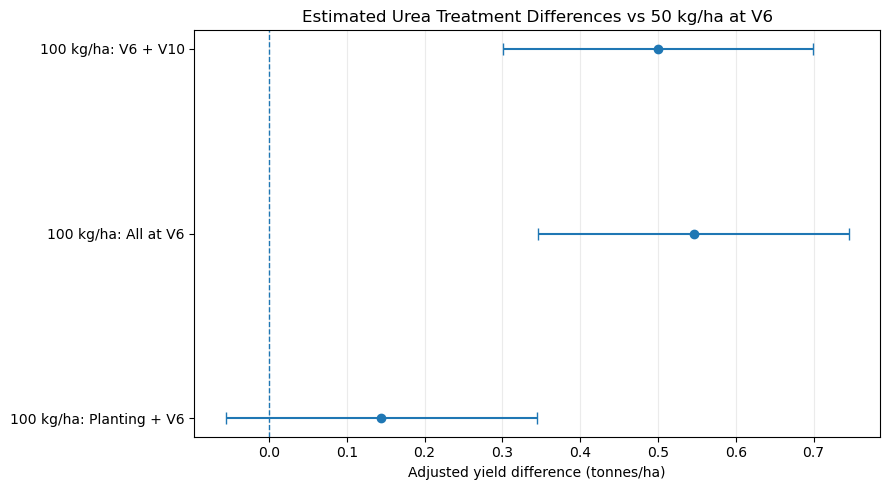

In [15]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Fixed-effect treatment estimates from the primary model
treatment_order = [
    "Urea1kg/Are(Planting+V6)",
    "Urea 1kg/Are(V6)",
    "Urea 1kg/Are(V6 + V10)"
]

rows = []

for term in treatment_terms:
    treatment_name = term.split("[T.")[-1].rstrip("]")

    rows.append({
        "treatment": treatment_name,
        "estimate": model_result.fe_params[term],
        "lower": model_result.conf_int().loc[term, 0],
        "upper": model_result.conf_int().loc[term, 1]
    })

treatment_results = pd.DataFrame(rows)

# Use readable labels for the figure
label_map = {
    "Urea1kg/Are(Planting+V6)": "100 kg/ha: Planting + V6",
    "Urea 1kg/Are(V6)": "100 kg/ha: All at V6",
    "Urea 1kg/Are(V6 + V10)": "100 kg/ha: V6 + V10"
}

treatment_results["label"] = treatment_results["treatment"].map(label_map)
treatment_results = treatment_results.set_index("treatment").loc[treatment_order].reset_index()

y_positions = np.arange(len(treatment_results))

fig, ax = plt.subplots(figsize=(9, 5))

ax.errorbar(
    treatment_results["estimate"],
    y_positions,
    xerr=[
        treatment_results["estimate"] - treatment_results["lower"],
        treatment_results["upper"] - treatment_results["estimate"]
    ],
    fmt="o",
    capsize=4
)

ax.axvline(0, linestyle="--", linewidth=1)
ax.set_yticks(y_positions)
ax.set_yticklabels(treatment_results["label"])
ax.set_xlabel("Adjusted yield difference (tonnes/ha)")
ax.set_title("Estimated Urea Treatment Differences vs 50 kg/ha at V6")
ax.grid(axis="x", alpha=0.25)

plt.tight_layout()
plt.show()